# Entangled quibits

In [38]:
from qiskit import *
from qiskit.visualization import plot_bloch_multivector, visualize_transition, plot_histogram
from qiskit.visualization import array_to_latex
from qiskit_aer import Aer
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.quantum_info import Operator
from IPython.display import display 

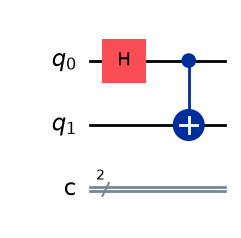

In [39]:
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.draw('mpl')

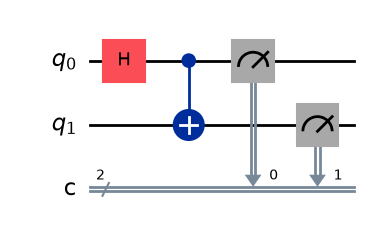

In [40]:
# qc.measure(0, 0)
# qc.measure(1, 1)

qc.measure([0, 1], [0, 1])
qc.draw('mpl')

In [41]:
# running the circuit into simulator with 1024 shots
backend = Aer.get_backend('qasm_simulator')
output = backend.run(qc, shots=1024).result().get_counts()

{'00': 499, '11': 525}


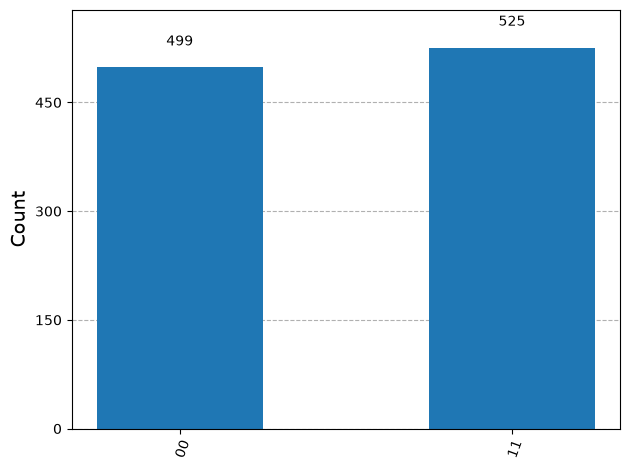

In [42]:
simulator = AerSimulator()
result = simulator.run(qc, shots=1024).result()
print(result.get_counts())
plot_histogram(result.get_counts())

In [43]:
qc_no_measure = qc.remove_final_measurements(inplace=False)

# Calculate the statevector
state = Statevector.from_instruction(qc_no_measure)

# Display the statevector in LaTeX format
display(array_to_latex(state, prefix="\\text{Statevector} = "))

<IPython.core.display.Latex object>

In [44]:
import sympy as sp
from IPython.display import display, Math

# Convert to a column matrix
state_column = sp.Matrix(state.data)
# Display as a LaTeX column vector
display(Math(
    r"|\psi\rangle = " + sp.latex(state_column)
))

<IPython.core.display.Math object>

In [45]:
from qiskit.quantum_info import Statevector
from IPython.display import display, Math
import sympy as sp

# Remove final measurements
qc_no_measure = qc.remove_final_measurements(inplace=False)

# Calculate the statevector
state = Statevector.from_instruction(qc_no_measure)

# Convert numerical amplitudes to exact symbolic expressions
state_column = sp.Matrix([
    sp.nsimplify(amplitude) for amplitude in state.data
])

# Display as a column vector with square roots
display(Math(
    r"|\psi\rangle = " + sp.latex(state_column)
))

<IPython.core.display.Math object>